In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [9]:
df = pd.read_excel("/content/Telco_customer_churn.xlsx")

In [10]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [11]:
df.isnull().sum()

,0
CustomerID,0
Count,0
Country,0
State,0
City,0
Zip Code,0
Lat Long,0
Latitude,0
Longitude,0
Gender,0


In [12]:
df['Churn Reason'].unique()

array(['Competitor made better offer', 'Moved',
       'Competitor had better devices',
       'Competitor offered higher download speeds',
       'Competitor offered more data', 'Price too high',
       'Product dissatisfaction', 'Service dissatisfaction',
       'Lack of self-service on Website', 'Network reliability',
       'Limited range of services',
       'Lack of affordable download/upload speed',
       'Long distance charges', 'Extra data charges', "Don't know",
       'Poor expertise of online support',
       'Poor expertise of phone support', 'Attitude of service provider',
       'Attitude of support person', 'Deceased', nan], dtype=object)

In [13]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [14]:
df['Count'].unique()

array([1])

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [16]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='object')

In [17]:
drop_cols = ['CustomerID','Count','Country','State','City','Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Churn Reason', 'Churn Value','Churn Score']
df = df.drop(drop_cols,axis=1)

In [18]:
df.columns

Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label',
       'CLTV'],
      dtype='object')

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             7043 non-null   object 
 1   Senior Citizen     7043 non-null   object 
 2   Partner            7043 non-null   object 
 3   Dependents         7043 non-null   object 
 4   Tenure Months      7043 non-null   int64  
 5   Phone Service      7043 non-null   object 
 6   Multiple Lines     7043 non-null   object 
 7   Internet Service   7043 non-null   object 
 8   Online Security    7043 non-null   object 
 9   Online Backup      7043 non-null   object 
 10  Device Protection  7043 non-null   object 
 11  Tech Support       7043 non-null   object 
 12  Streaming TV       7043 non-null   object 
 13  Streaming Movies   7043 non-null   object 
 14  Contract           7043 non-null   object 
 15  Paperless Billing  7043 non-null   object 
 16  Payment Method     7043 

In [20]:
df['Total Charges'] = df['Total Charges'].replace(' ',np.nan)

df['Total Charges'] = pd.to_numeric(df['Total Charges'])


print(df[df['Total Charges'].isna()]['Tenure Months'])


2234    0
2438    0
2568    0
2667    0
2856    0
4331    0
4687    0
5104    0
5719    0
6772    0
6840    0
Name: Tenure Months, dtype: int64


In [21]:
df['Total Charges'] = df['Total Charges'].fillna(0)

In [22]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder()
df['Churn Label'] = df['Churn Label'].map({'Yes': 1, 'No': 0})

df = pd.get_dummies(df,drop_first = True)

In [23]:
df.head()

,Tenure Months,Monthly Charges,Total Charges,Churn Label,CLTV,Gender_Male,Senior Citizen_Yes,Partner_Yes,Dependents_Yes,Phone Service_Yes,...,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_One year,Contract_Two year,Paperless Billing_Yes,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,2,53.85,108.15,1,3239,True,False,False,False,True,...,False,False,False,False,False,False,True,False,False,True
1,2,70.70,151.65,1,2701,False,False,False,True,True,...,False,False,False,False,False,False,True,False,True,False
2,8,99.65,820.50,1,5372,False,False,False,True,True,...,False,True,False,True,False,False,True,False,True,False
3,28,104.80,3046.05,1,5003,False,False,True,True,True,...,False,True,False,True,False,False,True,False,True,False
4,49,103.70,5036.30,1,5340,True,False,False,True,True,...,False,True,False,True,False,False,True,False,False,False


In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 32 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Tenure Months                           7043 non-null   int64  
 1   Monthly Charges                         7043 non-null   float64
 2   Total Charges                           7043 non-null   float64
 3   Churn Label                             7043 non-null   int64  
 4   CLTV                                    7043 non-null   int64  
 5   Gender_Male                             7043 non-null   bool   
 6   Senior Citizen_Yes                      7043 non-null   bool   
 7   Partner_Yes                             7043 non-null   bool   
 8   Dependents_Yes                          7043 non-null   bool   
 9   Phone Service_Yes                       7043 non-null   bool   
 10  Multiple Lines_No phone service         7043 non-null   bool

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,average_precision_score

In [26]:
pipeline = Pipeline([
    ('scaler',StandardScaler()),
    ('model',LogisticRegression())
])

X = df.drop(columns = 'Churn Label')
y = df['Churn Label']

In [27]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)


pipeline.fit(X_train,y_train)

y_pred = pipeline.predict(X_test)

print(accuracy_score(y_test,y_pred))
print(average_precision_score(y_test,y_pred))

0.8019872249822569
0.5111528995627189


In [28]:
from sklearn.model_selection import RandomizedSearchCV


param_distributions = {
    'model__C': np.logspace(-4, 4, 20),
    'model__penalty':['l1','l2'],
    'model__solver': ['liblinear','saga'],
    'model__max_iter'  : [1000,2500,5000]
}


random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    cv=5,
    scoring='average_precision',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train,y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                             ('model', LogisticRegression())]),
                   n_jobs=-1,
                   param_distributions={'model__C': array([1.00000000e-04, 2.63665090e-04, 6.95192796e-04, 1.83298071e-03,
       4.83293024e-03, 1.27427499e-02, 3.35981829e-02, 8.85866790e-02,
       2.33572147e-01, 6.15848211e-01, 1.62377674e+00, 4.28133240e+00,
       1.12883789e+01, 2.97635144e+01, 7.84759970e+01, 2.06913808e+02,
       5.45559478e+02, 1.43844989e+03, 3.79269019e+03, 1.00000000e+04]),
                                        'model__max_iter': [1000, 2500, 5000],
                                        'model__penalty': ['l1', 'l2'],
                                        'model__solver': ['liblinear', 'saga']},
                   random_state=42, scoring='average_precision', verbose=1)

In [29]:
print("Best Hyperparameters:", random_search.best_params_)
print("Best Validation Accuracy:", random_search.best_score_)


best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test)

Best Hyperparameters: {'model__solver': 'saga', 'model__penalty': 'l1', 'model__max_iter': 1000, 'model__C': np.float64(0.615848211066026)}
Best Validation Accuracy: 0.6719129984335558


In [30]:
from sklearn.ensemble import RandomForestClassifier

neg = len(y_train[y_train == 0])
pos = len(y_train[y_train == 1])
scale = neg/pos
scale

2.8352620830496935

In [31]:
rf = RandomForestClassifier(class_weight = 'balanced' , random_state = 42)

rf.fit(X_train,y_train)

y_pred_rf = rf.predict(X_test)

print(accuracy_score(y_test,y_pred_rf))
print(average_precision_score(y_test,y_pred_rf))

0.794180269694819
0.4897309082137705


In [32]:
param_distributions_rf = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'max_features' : ['auto', 'sqrt'],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'bootstrap': [True, False]
}

random_search_rf = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions_rf,
    n_iter=10,
    cv=5,
    scoring='average_precision',
)

random_search_rf.fit(X_train,y_train)

print("Best Hyperparameters of Random Forest:", random_search_rf.best_params_)
print("Best Validation PR-AUC:", random_search_rf.best_score_)


best_model_rf = random_search_rf.best_estimator_
y_probs_rf = best_model_rf.predict_proba(X_test)[:,1]

true_pr_auc = average_precision_score(y_test, y_probs_rf)
print("True Test PR-AUC for Random Forest:", true_pr_auc)

Best Hyperparameters of Random Forest: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20, 'bootstrap': False}
Best Validation PR-AUC: 0.6254461750140392
True Test PR-AUC for Random Forest: 0.6665663384128098


In [33]:
from xgboost import XGBClassifier

# 1. Calculate the imbalance ratio
neg = len(y_train[y_train == 0])
pos = len(y_train[y_train == 1])
scale = neg / pos

xgb = XGBClassifier(
    scale_pos_weight=scale,
    random_state=42,
    eval_metric='aucpr'
)

param_distributions_xgb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5, 6, 7],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5]
}

random_search_xgb = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_distributions_xgb,
    n_iter=15,
    cv=5,
    scoring='average_precision',
    random_state=42,
    n_jobs=-1
)

random_search_xgb.fit(X_train, y_train)

print("Best Hyperparameters of XGBoost:", random_search_xgb.best_params_)
print("Best Validation PR-AUC:", random_search_xgb.best_score_)

best_model_xgb = random_search_xgb.best_estimator_
y_probs_xgb = best_model_xgb.predict_proba(X_test)[:, 1]

true_pr_auc_xgb = average_precision_score(y_test, y_probs_xgb)
print("True Test PR-AUC for XGBoost:", true_pr_auc_xgb)

Best Hyperparameters of XGBoost: {'subsample': 0.6, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.01, 'colsample_bytree': 0.6}
Best Validation PR-AUC: 0.675100208321955
True Test PR-AUC for XGBoost: 0.6945189776766225


In [34]:
np.random.seed(42)

df['treatment'] = np.random.binomial(1,0.5,size = len(df))

In [35]:
df['treatment'].value_counts()

,count
treatment,
0,3545
1,3498


In [36]:
def calculate_true_uplift(row):
  if row['Tenure Months'] > 40:
    return 0.01

  is_month_to_month = (row['Contract_One year'] == 0) and (row['Contract_Two year'] == 0)
  if is_month_to_month and row['Monthly Charges'] > 100:
    return 0.02

  return 0.20

df['true_uplift'] = df.apply(calculate_true_uplift,axis = 1)

In [37]:
print(df[['Tenure Months', 'Monthly Charges', 'Contract_One year', 'Contract_Two year', 'true_uplift']].head(10))

   Tenure Months  Monthly Charges  Contract_One year  Contract_Two year  \
0              2            53.85              False              False   
1              2            70.70              False              False   
2              8            99.65              False              False   
3             28           104.80              False              False   
4             49           103.70              False              False   
5             10            55.20              False              False   
6              1            39.65              False              False   
7              1            20.15              False              False   
8             47            99.35              False              False   
9              1            30.20              False              False   

   true_uplift  
0         0.20  
1         0.20  
2         0.20  
3         0.02  
4         0.01  
5         0.20  
6         0.20  
7         0.20  
8         0.01  
9   

In [38]:
new_churn_labels = []

for index,row in df.iterrows():
  if row['treatment'] == 0:
    new_churn_labels.append(row['Churn Label'])
  else:
    if row['Churn Label'] == 0:
      new_churn_labels.append(0)
    else:
      if np.random.random() < row['true_uplift']:
        new_churn_labels.append(0)
      else:
        new_churn_labels.append(1)

df['observed_churn'] = new_churn_labels

print("Control Group Churn Rate:", df[df['treatment'] == 0]['observed_churn'].mean())
print("Treatment Group Churn Rate:", df[df['treatment'] == 1]['observed_churn'].mean())

Control Group Churn Rate: 0.26064880112834976
Treatment Group Churn Rate: 0.225557461406518


In [39]:
treated_df = df[df['treatment'] == 0]
control_df = df[df['treatment'] == 1]

drop_cols = ['Churn Label','observed_churn','true_uplift']

X_treated = treated_df.drop(columns = drop_cols)
y_treated = treated_df['observed_churn']

X_control = control_df.drop(columns = drop_cols)
y_control = control_df['observed_churn']

model_t = XGBClassifier(random_state=42,eval_metric='aucpr')
model_t.fit(X_treated,y_treated)

model_c = XGBClassifier(random_state=42,eval_metric='aucpr')
model_c.fit(X_control,y_control)

print("Both models trained successfully!")

Both models trained successfully!


In [40]:
# 1. Prepare the features for the whole dataset (drop the target/leakage cols)
X_score = df.drop(columns=['Churn Label', 'observed_churn', 'true_uplift'])

# 2. Get churn probabilities from BOTH models for EVERY customer
# Model C: What is their natural churn risk?
prob_control = model_c.predict_proba(X_score)[:, 1]

# Model T: What is their churn risk if we give them a discount?
prob_treated = model_t.predict_proba(X_score)[:, 1]

# 3. Calculate Uplift!
# Uplift = (Natural Risk) - (Risk if Treated)
# If this number is high, the discount saves them.
df['predicted_uplift'] = prob_control - prob_treated

# 4. Let's look at the results!
print(df[['predicted_uplift', 'true_uplift']].head(10))

   predicted_uplift  true_uplift
0         -0.212532         0.20
1         -0.401759         0.20
2         -0.113464         0.20
3          0.799404         0.02
4         -0.662400         0.01
5         -0.550040         0.20
6         -0.031573         0.20
7          0.285992         0.20
8          0.560475         0.01
9         -0.015679         0.20


In [41]:
from scipy.stats import spearmanr

# Spearman correlation checks if the RANKING of your predictions
# matches the RANKING of the true uplift.
correlation, _ = spearmanr(df['predicted_uplift'], df['true_uplift'])
print(f"Spearman Correlation between Predicted and True Uplift: {correlation:.3f}")

Spearman Correlation between Predicted and True Uplift: -0.160


In [42]:
# 1. Save the prob_control as a column (Fixes the KeyError)
df['prob_control'] = prob_control

# 2. We want to target 20% of the customer base
budget = int(0.20 * len(df))

# --- STRATEGY 1: UPLIFT MODEL ---
# Sort by predicted uplift (LOWEST to HIGHEST because the model learned backwards)
uplift_sorted = df.sort_values('predicted_uplift', ascending=True)
uplift_targeted = uplift_sorted.head(budget)
uplift_saved = uplift_targeted['true_uplift'].sum()

# --- STRATEGY 2: CHURN MODEL (The naive approach) ---
# Sort by natural churn risk (HIGHEST to LOWEST)
churn_sorted = df.sort_values('prob_control', ascending=False)
churn_targeted = churn_sorted.head(budget)
churn_saved = churn_targeted['true_uplift'].sum()

# --- STRATEGY 3: RANDOM TARGETING ---
random_targeted = df.sample(n=budget, random_state=42)
random_saved = random_targeted['true_uplift'].sum()

print(f"Total customers targeted: {budget}")
print("-" * 30)
print(f"Churns saved by Random Targeting:        {random_saved:.1f} customers")
print(f"Churns saved by Churn Probability Model: {churn_saved:.1f} customers")
print(f"Churns saved by Uplift Model:            {uplift_saved:.1f} customers")

Total customers targeted: 1408
------------------------------
Churns saved by Random Targeting:        171.8 customers
Churns saved by Churn Probability Model: 216.5 customers
Churns saved by Uplift Model:            230.3 customers


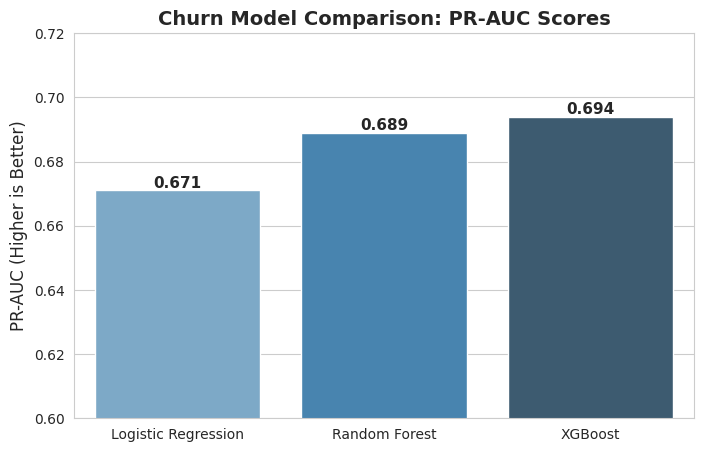

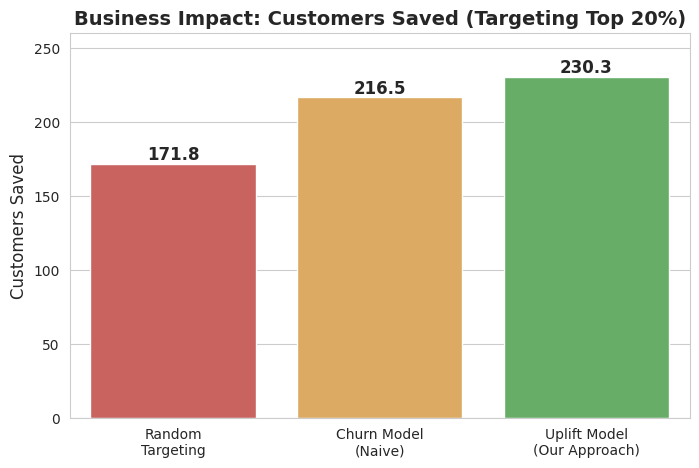

In [43]:
# Set style
sns.set_style("whitegrid")

# ---------------------------------------------------------
# CHART 1: Churn Model Comparison (PR-AUC)
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
models = ['Logistic Regression', 'Random Forest', 'XGBoost']
scores = [0.671, 0.689, 0.694]

ax = sns.barplot(x=models, y=scores, palette="Blues_d")
plt.title('Churn Model Comparison: PR-AUC Scores', fontsize=14, fontweight='bold')
plt.ylabel('PR-AUC (Higher is Better)', fontsize=12)
plt.ylim(0.60, 0.72)

# Add scores on top of bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.show()


# ---------------------------------------------------------
# CHART 2: The Business Impact (Uplift vs Churn vs Random)
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
strategies = ['Random\nTargeting', 'Churn Model\n(Naive)', 'Uplift Model\n(Our Approach)']
saved = [171.8, 216.5, 230.3]
colors = ['#d9534f', '#f0ad4e', '#5cb85c'] # Red, Orange, Green

ax2 = sns.barplot(x=strategies, y=saved, palette=colors)
plt.title('Business Impact: Customers Saved (Targeting Top 20%)', fontsize=14, fontweight='bold')
plt.ylabel('Customers Saved', fontsize=12)
plt.ylim(0, 260)

# Add scores on top of bars
for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.1f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.show()

In [45]:
pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 81.5 MB/s eta 0:00:00
